In [1]:
from IPython.core.interactiveshell import InteractiveShell as IS; IS.ast_node_interactivity = "all"
import numpy as np, pandas as pd, time, matplotlib.pyplot as plt, seaborn as sns # tensorflow_addons as tfa
from sklearn.preprocessing import PolynomialFeatures
import tensorflow as tf, tensorflow.keras as keras
ToCSV = lambda df, fname: df.round(2).to_csv(f'{fname}.csv', index_label='ID') # rounds values to 2 decimals

In [2]:
df = pd.read_csv('XY_Bacteria.csv'); df

,A0T0G0C10,A0T0G1C9,A0T0G2C8,A0T0G3C7,A0T0G4C6,A0T0G5C5,A0T0G6C4,A0T0G7C3,A0T0G8C2,A0T0G9C1,...,A8T0G1C1,A8T0G2C0,A8T1G0C1,A8T1G1C0,A8T2G0C0,A9T0G0C1,A9T0G1C0,A9T1G0C0,A10T0G0C0,y
0,10,32,41,39,77,122,55,81,58,31,...,38,88,80,20,36,31,32,32,10,NaN
1,10,31,52,165,225,221,150,143,48,31,...,111,125,143,159,69,45,32,71,10,NaN
2,10,31,66,107,142,156,142,107,66,31,...,93,66,968,93,66,31,31,31,10,NaN
3,2,19,25,34,83,90,74,57,27,27,...,29,30,39,29,23,21,21,19,2,NaN
4,10,31,66,107,280,156,143,107,67,31,...,297,66,93,297,66,31,31,31,10,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,10,31,66,107,143,155,142,107,67,31,...,93,66,93,93,66,31,31,31,10,2.0
99996,10,31,66,108,142,155,142,107,67,31,...,93,426,93,93,66,31,31,31,10,2.0
99997,10,31,66,108,143,155,143,107,66,31,...,93,66,93,93,66,31,31,31,10,3.0
99998,10,31,66,107,142,155,142,107,66,31,...,93,66,93,93,66,31,31,31,10,4.0


In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold,cross_validate,GroupKFold,cross_val_score,GridSearchCV,StratifiedGroupKFold,StratifiedShuffleSplit
from itertools import combinations, product
from sklearn.metrics import accuracy_score, f1_score
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,PolynomialFeatures, OneHotEncoder,  FunctionTransformer, Normalizer
from sklearn.pipeline import make_pipeline, Pipeline, clone

In [4]:
df_train = df[df.isnull()['y']==False]
df_train = df_train.drop_duplicates()
df_test = df.query('y!=y').drop('y', axis=1)

NumFeatures = df_train.columns.drop(['y'])

clean = False

if clean:
    #clean up outliers and unrealistic data
    lower = df_train.quantile(0.0001)
    upper = df_train.quantile(0.9999)

    mask = df_train.ge(lower) & df_train.le(upper)

    df_train_clean = df_train[mask.all(axis=1)]
else:
    df_train_clean = df_train

X_clean = df_train_clean.drop(columns='y')
y_clean = df_train_clean['y']

In [5]:
class F1Score(tf.keras.metrics.Metric):
    def __init__(self, name='f1_score', threshold=0.5, **kwargs):
        super().__init__(name=name, **kwargs)
        self.threshold = threshold

        self.tp = self.add_weight(name='tp', initializer='zeros')
        self.fp = self.add_weight(name='fp', initializer='zeros')
        self.fn = self.add_weight(name='fn', initializer='zeros')

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = tf.cast(tf.reshape(y_true, [-1]) >= 0.5, tf.float32)
        y_pred = tf.cast(
            tf.reshape(y_pred, [-1]) >= self.threshold,
            tf.float32
        )

        self.tp.assign_add(tf.reduce_sum(y_true * y_pred))
        self.fp.assign_add(tf.reduce_sum((1 - y_true) * y_pred))
        self.fn.assign_add(tf.reduce_sum(y_true * (1 - y_pred)))

    def result(self):
        precision = self.tp / (self.tp + self.fp + tf.keras.backend.epsilon())
        recall = self.tp / (self.tp + self.fn + tf.keras.backend.epsilon())

        return 2 * precision * recall / (
            precision + recall + tf.keras.backend.epsilon()
        )

    def reset_state(self):
        self.tp.assign(0.0)
        self.fp.assign(0.0)
        self.fn.assign(0.0)

In [6]:
class MulticlassF1Score(tf.keras.metrics.Metric):
    def __init__(self, num_classes, average='macro',
                 name='f1_score', **kwargs):
        super().__init__(name=name, **kwargs)

        self.num_classes = num_classes
        self.average = average

        self.cm = self.add_weight(
            name='confusion_matrix',
            shape=(num_classes, num_classes),
            initializer='zeros'
        )

    def update_state(self, y_true, y_pred, sample_weight=None):
        # Convert one-hot labels to class IDs if necessary
        if y_true.shape.rank is not None and y_true.shape.rank > 1:
            y_true = tf.argmax(y_true, axis=-1)

        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)

        # Convert predicted probabilities to class IDs
        y_pred = tf.argmax(y_pred, axis=-1)
        y_pred = tf.cast(tf.reshape(y_pred, [-1]), tf.int32)

        # Accumulate confusion matrix
        cm = tf.math.confusion_matrix(
            y_true,
            y_pred,
            num_classes=self.num_classes,
            weights=sample_weight,
            dtype=self.dtype
        )

        self.cm.assign_add(cm)

    def result(self):
        tp = tf.linalg.diag_part(self.cm)
        fp = tf.reduce_sum(self.cm, axis=0) - tp
        fn = tf.reduce_sum(self.cm, axis=1) - tp

        precision = tp / (tp + fp + tf.keras.backend.epsilon())
        recall = tp / (tp + fn + tf.keras.backend.epsilon())

        f1 = 2 * precision * recall / (
            precision + recall + tf.keras.backend.epsilon()
        )

        if self.average == 'macro':
            return tf.reduce_mean(f1)

        elif self.average == 'micro':
            total_tp = tf.reduce_sum(tp)
            total_fp = tf.reduce_sum(fp)
            total_fn = tf.reduce_sum(fn)

            precision = total_tp / (
                total_tp + total_fp + tf.keras.backend.epsilon()
            )
            recall = total_tp / (
                total_tp + total_fn + tf.keras.backend.epsilon()
            )

            return 2 * precision * recall / (
                precision + recall + tf.keras.backend.epsilon()
            )

        elif self.average == 'weighted':
            support = tf.reduce_sum(self.cm, axis=1)
            return tf.reduce_sum(f1 * support) / (
                tf.reduce_sum(support) + tf.keras.backend.epsilon()
            )

        else:
            raise ValueError(
                "average must be 'macro', 'micro', or 'weighted'"
            )

    def reset_state(self):
        self.cm.assign(tf.zeros_like(self.cm))

In [26]:
#binning potential candidate

selection = [
    # 'A0T4G2C4',
    # 'A0T9G1C0',
    # 'A1T4G2C3',
    # 'A2T7G1C0',
    # 'A1T3G4C2',
    # 'A1T3G3C3',
    # 'A2T2G2C4',

    'A0T9G1C0',
    'A1T4G4C1',
    'A2T2G3C3',
    'A3T2G0C5',
    'A4T4G1C1',
    'A5T4G0C1',
    'A4T1G4C1',
]

selection2 = [
    'A0T4G2C4',
    'A0T9G1C0',
    'A1T4G2C3',
    'A2T7G1C0',
    'A1T3G4C2',
    'A1T3G3C3',
    'A2T2G2C4',

    # 'A0T9G1C0',
    # 'A1T4G4C1',
    # 'A2T2G3C3',
    # 'A3T2G0C5',
    # 'A4T4G1C1',
    # 'A5T4G0C1',
    # 'A4T1G4C1',
]


,"n_components n_components: int, default=1The number of mixture components.",5
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'tied'
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",500
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


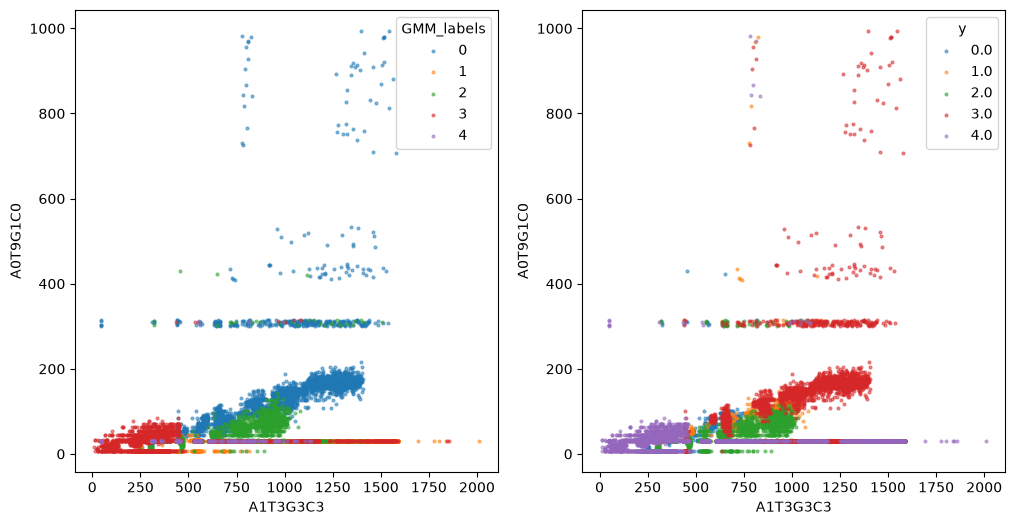

In [8]:
from sklearn.mixture import GaussianMixture

X_clean_train, X_clean_val, y_clean_train, y_clean_val = train_test_split(
    X_clean,
    y_clean,
    train_size=0.2,
    stratify=y_clean,
    shuffle=True,
    random_state=42
)

clustering_preprocessor_pipeline = Pipeline([
    ("log", FunctionTransformer(np.log1p,inverse_func=np.expm1)),
    ("l1norm",Normalizer(norm="l1")),
    ("scaler", StandardScaler())
]).set_output(transform="pandas")

X_clean_train_prepped = clustering_preprocessor_pipeline.fit_transform(X_clean_train)

gmm = GaussianMixture(n_components=5, 
                      covariance_type='tied', #"full","tied", "diag", "spherical"
                      random_state=42,    
                    #   init_params='kmeans',   # <-- deterministic initialization
                        max_iter=500)

gmm.fit(X_clean_train_prepped[selection])

labels = gmm.predict(X_clean_train_prepped[selection])
labels_series = pd.Series(labels, index=X_clean_train_prepped.index, name="gmm_label")

width_unit = 2
height_unit = 1
fig, axs = plt.subplots(height_unit, width_unit, figsize=(6*width_unit, 6*height_unit))
c1 = 'A1T3G3C3'
c2 = 'A0T9G1C0'
for group, data in X_clean_train.groupby(labels_series):
    __ = axs[0].scatter(data[c1],data[c2],alpha=0.5,label=group,s=4)
            
    __ = axs[0].legend(title="GMM_labels")

__ = axs[0].set_xlabel(c1)
__ = axs[0].set_ylabel(c2)
    
for group, data in X_clean_train.groupby(y_clean_train):
    __ = axs[1].scatter(data[c1],data[c2],alpha=0.5,label=group,s=4)
            
    __ = axs[1].legend(title="y")

__ = axs[1].set_xlabel(c1)
__ = axs[1].set_ylabel(c2)

plt.show()


In [14]:
seed = [
        2,
        12,
        22,
        32,
        42
        ]
accu = []
f1 = []

for s in seed:
    X_clean_train, X_clean_val, y_clean_train, y_clean_val = train_test_split(
        X_clean,
        y_clean,
        train_size=0.8,
        stratify=y_clean,
        shuffle=True,
        # random_state=42
        random_state=s
    )

    # Preprocess training data and predict GMM cluster probabilities
    X_train_prepped_all = clustering_preprocessor_pipeline.transform(X_clean_train)
    gmm_features_train = gmm.predict_proba(X_train_prepped_all[selection])

    # Preprocess validation data and predict GMM cluster probabilities
    X_val_prepped_all = clustering_preprocessor_pipeline.transform(X_clean_val)
    gmm_features_val = gmm.predict_proba(X_val_prepped_all[selection])

    # Append GMM cluster probabilities as new columns
    X_clean_train_with_gmm = np.hstack([X_clean_train.values, gmm_features_train])
    X_clean_val_with_gmm = np.hstack([X_clean_val.values, gmm_features_val])

    tf.keras.utils.set_random_seed(0)

    Init = keras.initializers.RandomNormal(seed=0)

    input_layer = keras.layers.Input(shape=(X_clean_train_with_gmm.shape[1],),name="input")

    input_norm = keras.layers.BatchNormalization()(input_layer)

    # Block 0: 256 units
    h = keras.layers.Dense(384, use_bias=False, name="dense_0")(input_norm)
    # h = keras.layers.BatchNormalization(name="bn_1")(h)
    h = keras.layers.Activation("relu", name="act_0")(h)
    # h = keras.layers.Dropout(0.1)(h)

    # Block 1: 256 units
    h = keras.layers.Dense(256, use_bias=False, name="dense_1")(h)
    # h = keras.layers.BatchNormalization(name="bn_1")(h)
    h = keras.layers.Activation("relu", name="act_1")(h)
    # h = keras.layers.Dropout(0.1)(h)

    # Block 1: 128 units
    h = keras.layers.Dense(128, use_bias=False, name="dense_11")(h)
    # h = keras.layers.BatchNormalization(name="bn_1")(h)
    h = keras.layers.Activation("relu", name="act_11")(h)
    # h = keras.layers.Dropout(0.1)(h)

    # Block 2: 64 units
    h = keras.layers.Dense(64, use_bias=False, name="dense_2")(h)
    # h = keras.layers.BatchNormalization(name="bn_2")(h)
    h = keras.layers.Activation("relu", name="act_2")(h)
    # h = layers.Dropout(0.1)(h)

    # Block 2: 32 units
    h = keras.layers.Dense(32, use_bias=False, name="dense_3")(h)
    # h = keras.layers.BatchNormalization(name="bn_3")(h)
    h = keras.layers.Activation("relu", name="act_3")(h)

    out = keras.layers.Dense(10, activation='softmax', name='output')(h)

    m = keras.Model(inputs=input_layer, outputs=out)

    m.compile(loss="sparse_categorical_crossentropy",
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              metrics=[
                        "accuracy",
                       MulticlassF1Score(
                        num_classes=10,
                        average='macro'
                    )])

    m.fit(
        X_clean_train_with_gmm,
        y_clean_train.values,

        epochs=35,
        batch_size=1024,
        verbose=0
    )

    y_pred = np.argmax(m.predict(X_clean_val_with_gmm, verbose=0),axis=1)


    accu += [accuracy_score(y_clean_val, y_pred)]
    f1 += [f1_score(y_clean_val, y_pred,average='macro')]

print(f'mean:{np.mean(accu):.4f},std {np.std(accu):.4f} | ', end="")
print(f'f1: {np.mean(f1):.4f},std {np.std(f1):.4f}')

mean:0.9942,std 0.0012 | f1: 0.9865,std 0.0029


In [ ]:
seed = [
        2,
        12,
        22,
        32,
        42
        ]
accu = []
f1 = []

for s in seed:
    X_clean_train, X_clean_val, y_clean_train, y_clean_val = train_test_split(
        X_clean,
        y_clean,
        train_size=0.8,
        stratify=y_clean,
        shuffle=True,
        # random_state=42
        random_state=s
    )

    # Preprocess training data and predict GMM cluster probabilities
    X_train_prepped_all = clustering_preprocessor_pipeline.transform(X_clean_train)
    gmm_features_train = gmm.predict_proba(X_train_prepped_all[selection])

    # Preprocess validation data and predict GMM cluster probabilities
    X_val_prepped_all = clustering_preprocessor_pipeline.transform(X_clean_val)
    gmm_features_val = gmm.predict_proba(X_val_prepped_all[selection])

    # LATE FUSION CHANGE: Do not hstack here. Keep them as separate arrays.
    
    tf.keras.utils.set_random_seed(0)
    Init = keras.initializers.RandomNormal(seed=0)

    # LATE FUSION CHANGE: Create TWO distinct input layers
    input_dna = keras.layers.Input(shape=(X_clean_train.shape[1],), name="input_dna")
    input_gmm = keras.layers.Input(shape=(gmm_features_train.shape[1],), name="input_gmm")

    # Only normalize the raw DNA features
    input_norm = keras.layers.BatchNormalization()(input_dna)

    # Block 0: 256 units (Deep Path for DNA counts)
    h = keras.layers.Dense(256, use_bias=False, name="dense_0")(input_norm)
    h = keras.layers.Activation("relu", name="act_0")(h)

    # Block 1: 256 units
    h = keras.layers.Dense(256, use_bias=False, name="dense_1")(h)
    h = keras.layers.Activation("relu", name="act_1")(h)

    # h = keras.layers.Concatenate(name="late_fusion_concat")([h, input_gmm])

    # Block 1: 128 units
    h = keras.layers.Dense(128, use_bias=False, name="dense_11")(h)
    h = keras.layers.Activation("relu", name="act_11")(h)

    # LATE FUSION CHANGE: Concatenate the GMM probabilities with the 64-unit output
    h = keras.layers.Concatenate(name="late_fusion_concat")([h, input_gmm])

    # Block 2: 64 units
    h = keras.layers.Dense(64, use_bias=False, name="dense_2")(h)
    h = keras.layers.Activation("relu", name="act_2")(h)

    # LATE FUSION CHANGE: Concatenate the GMM probabilities with the 64-unit output
    # h = keras.layers.Concatenate(name="late_fusion_concat")([h, input_gmm])

    # Block 2: 32 units (Processing the combined DNA extraction + GMM probs)
    h = keras.layers.Dense(32, use_bias=False, name="dense_3")(h)
    h = keras.layers.Activation("relu", name="act_3")(h)

    # h = keras.layers.Concatenate(name="late_fusion_concat")([h, input_gmm])

    out = keras.layers.Dense(10, activation='softmax', name='output')(h)

    # LATE FUSION CHANGE: Model now takes a list of inputs
    m = keras.Model(inputs=[input_dna, input_gmm], outputs=out)

    m.compile(loss="sparse_categorical_crossentropy",
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              metrics=[
                        "accuracy",
                        MulticlassF1Score(
                        num_classes=10,
                        average='macro'
                    )])

    # LATE FUSION CHANGE: Pass the inputs as a list to fit()
    m.fit(
        [X_clean_train.values, gmm_features_train],
        y_clean_train.values,
        epochs=35,
        batch_size=1024,
        verbose=0
    )

    # LATE FUSION CHANGE: Pass the inputs as a list to predict()
    y_pred = np.argmax(m.predict([X_clean_val.values, gmm_features_val], verbose=0), axis=1)

    accu += [accuracy_score(y_clean_val, y_pred)]
    f1 += [f1_score(y_clean_val, y_pred, average='macro')]

print(f'mean:{np.mean(accu):.4f},std {np.std(accu):.4f} | ', end="")
print(f'f1: {np.mean(f1):.4f},std {np.std(f1):.4f}')

mean:0.9893,std 0.0085 | f1: 0.9773,std 0.0168


|accu|f1|layers|optimize|epochs|batch size|
|---|---|---|---|---|---|
|0.9938,0.0002|0.9856,0.0006|256,128,64,32,1|batch norm on input,no outlier remove, new API and no initialize|35|1024|
|0.9940,0.0006|0.9859,0.0017|256,196,128,32,1|batch norm on input,no outlier remove, new API and no initialize|35|1024|
|0.9945,0.0012|0.9874,0.0028|256,256,128,64,32,1|batch norm on input,no outlier remove, new API and no initialize|35|1024|
|0.9947,0.0009|0.9877,0.0020|256,256,128,64,32,1|batch norm on input,no outlier remove, new API and no initialize, wide append after 128|35|1024|
|0.9936,0.0013|0.9855,0.0030|256,256,128,64,32,1|batch norm on input,no outlier remove, new API and no initialize, wide append after 2nd 256|35|1024|
|0.9928,0.0015|0.9842,0.0026|256,256,128,64,32,1|batch norm on input,no outlier remove, new API and no initialize, wide append after 32|35|1024|
|0.9904,0.0048|0.9779,0.0115|256,256,128,64,32,1|batch norm on input,no outlier remove, new API and no initialize, wide append after 64|35|1024|
|0.9944,0.0014|0.9875,0.0025|384,256,128,64,32,1|batch norm on input,no outlier remove, new API and no initialize, wide append after 128|35|1024|


In [33]:
gmm2 = GaussianMixture(n_components=5, 
                      covariance_type='tied', #"full","tied", "diag", "spherical"
                      random_state=42,    
                    #   init_params='kmeans',   # <-- deterministic initialization
                        max_iter=500)

gmm2.fit(X_clean_train_prepped[selection2])

seed = [
        2,
        12,
        22,
        32,
        42
        ]
accu = []
f1 = []

for s in seed:
    X_clean_train, X_clean_val, y_clean_train, y_clean_val = train_test_split(
        X_clean,
        y_clean,
        train_size=0.8,
        stratify=y_clean,
        shuffle=True,
        # random_state=42
        random_state=s
    )

    # Preprocess training data and predict GMM cluster probabilities
    X_train_prepped_all = clustering_preprocessor_pipeline.transform(X_clean_train)
    gmm_features_train = gmm.predict_proba(X_train_prepped_all[selection])
    gmm2_features_train = gmm2.predict_proba(X_train_prepped_all[selection2])

    # Preprocess validation data and predict GMM cluster probabilities
    X_val_prepped_all = clustering_preprocessor_pipeline.transform(X_clean_val)
    gmm_features_val = gmm.predict_proba(X_val_prepped_all[selection])
    gmm2_features_val = gmm2.predict_proba(X_val_prepped_all[selection2])

    # LATE FUSION CHANGE: Do not hstack here. Keep them as separate arrays.
    
    tf.keras.utils.set_random_seed(0)
    Init = keras.initializers.RandomNormal(seed=0)

    # LATE FUSION CHANGE: Create TWO distinct input layers
    input_dna = keras.layers.Input(shape=(X_clean_train.shape[1],), name="input_dna")
    input_gmm = keras.layers.Input(shape=(gmm_features_train.shape[1],), name="input_gmm")
    input_gmm2 = keras.layers.Input(shape=(gmm2_features_train.shape[1],), name="input_gmm2")

    # Only normalize the raw DNA features
    input_norm = keras.layers.BatchNormalization()(input_dna)

    # h = keras.layers.Concatenate(name="late_fusion_concat1")([input_norm, input_gmm ,input_gmm2])

    # Block 0: 256 units (Deep Path for DNA counts)
    h = keras.layers.Dense(256, use_bias=False, name="dense_0")(input_norm)
    # h = keras.layers.Dense(256, use_bias=False, name="dense_0")(h)
        
    h = keras.layers.Activation("relu", name="act_0")(h)

    # h = keras.layers.Concatenate(name="late_fusion_concat1")([h, input_gmm2])

    # Block 1: 256 units
    h = keras.layers.Dense(256, use_bias=False, name="dense_1")(h)
    h = keras.layers.Activation("relu", name="act_1")(h)

    # h = keras.layers.Concatenate(name="late_fusion_concat1")([h, input_gmm2])

    # Block 1: 128 units
    h = keras.layers.Dense(128, use_bias=False, name="dense_11")(h)
    h = keras.layers.Activation("relu", name="act_11")(h)

    # LATE FUSION CHANGE: Concatenate the GMM probabilities with the 64-unit output
    h = keras.layers.Concatenate(name="late_fusion_concat2")([h, input_gmm2])

    # Block 2: 64 units
    h = keras.layers.Dense(64, use_bias=False, name="dense_2")(h)
    h = keras.layers.Activation("relu", name="act_2")(h)

    # LATE FUSION CHANGE: Concatenate the GMM probabilities with the 64-unit output
    # h = keras.layers.Concatenate(name="late_fusion_concat")([h, input_gmm])

    # Block 2: 32 units (Processing the combined DNA extraction + GMM probs)
    h = keras.layers.Dense(32, use_bias=False, name="dense_3")(h)
    h = keras.layers.Activation("relu", name="act_3")(h)

    # h = keras.layers.Concatenate(name="late_fusion_concat")([h, input_gmm])

    out = keras.layers.Dense(10, activation='softmax', name='output')(h)

    # LATE FUSION CHANGE: Model now takes a list of inputs
    m = keras.Model(inputs=[input_dna, input_gmm, input_gmm2], outputs=out)

    m.compile(loss="sparse_categorical_crossentropy",
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              metrics=[
                        "accuracy",
                        MulticlassF1Score(
                        num_classes=10,
                        average='macro'
                    )])

    # LATE FUSION CHANGE: Pass the inputs as a list to fit()
    m.fit(
        [X_clean_train.values, gmm_features_train, gmm2_features_train],
        y_clean_train.values,
        epochs=35,
        batch_size=1024,
        verbose=0
    )

    # LATE FUSION CHANGE: Pass the inputs as a list to predict()
    y_pred = np.argmax(m.predict([X_clean_val.values, gmm_features_val, gmm2_features_val], verbose=0), axis=1)

    accu += [accuracy_score(y_clean_val, y_pred)]
    f1 += [f1_score(y_clean_val, y_pred, average='macro')]

print(f'mean:{np.mean(accu):.4f},std {np.std(accu):.4f} | ', end="")
print(f'f1: {np.mean(f1):.4f},std {np.std(f1):.4f}')

,"n_components n_components: int, default=1The number of mixture components.",5
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'tied'
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",500
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


mean:0.9940,std 0.0018 | f1: 0.9861,std 0.0038
